In [14]:
import pandas as pd
import numpy as np
import neurokit2 as nk
import pyedflib
import os

In [15]:
def find_patient_ecg_path(base_path, patient):
    for folder in os.listdir(base_path):
        if patient in folder:
            path = os.path.join(base_path, folder, 'ePatch', 'Extracted (from EDF converter)')
            if os.path.exists(path):
                return path
    print(f"The path for patient {patient} not found.")
    return None


def process_ecg_files(ecg_path, lead=0):
    if ecg_path is None:
        return None
    ecg_files = [os.path.join(ecg_path, file) for file in os.listdir(ecg_path) if file.endswith('.edf')]
    if len(ecg_files) == 0:
        print(f"No ECG files found for patient {ecg_path}.")
        return None
    # Read edf files and concatenate them if there are multiple files
    ecg_data = []
    for file in ecg_files:
        with pyedflib.EdfReader(file) as f:
            ecg_data.append(f.readSignal(lead))
    ecg_data = np.concatenate(ecg_data)
    return (ecg_data, f.getSampleFrequency(0))

In [16]:
def count_ecg_quality(patient, time_window=20, lead=0):
    base_path = '../data/01NVa_Sepsis/RAW_DATA/'
    ecg_path = find_patient_ecg_path(base_path, patient)
    ecg_files = process_ecg_files(ecg_path, lead=lead)
    if ecg_files is None:
        return None
    ecg_data, sampling_rate = ecg_files

    window_size = int(time_window * sampling_rate)
    res = dict()
    for i in range(0, len(ecg_data), window_size):
        window_ecg = ecg_data[i:i+window_size]
        if len(window_ecg) < window_size:
            continue
        # Clean the ECG signal
        ecg_signal = nk.ecg_clean(window_ecg, sampling_rate=sampling_rate)
        quality = nk.ecg_quality(ecg_signal, sampling_rate=sampling_rate, method='zhao2018')
        res[quality] = res.get(quality, 0) + 1
    return [res.get('Unacceptable', 0), res.get('Barely acceptable', 0), res.get('Excellent', 0)]

In [17]:
# calculate for all patients and save the results in a csv file, where each row is a patient and each column is the count of the quality
def count_all_patients():
    res = []
    for i in range(1001, 1260):
        res1, res2 = count_ecg_quality(f"003-{i}", lead=0), count_ecg_quality(f"003-{i}", lead=1)
        if res1 is None or res2 is None:
            continue
        res.append([f"003-{i}", *res1, *res2])
        print(f"Patient 003-{i}: {res1}, {res2}")
    res = pd.DataFrame(res, columns=['Patient', 'Unacceptable_lead0', 'Barely acceptable_lead0', 'Excellent_lead0', 'Unacceptable_lead1', 'Barely acceptable_lead1', 'Excellent_lead1'])
    res.to_csv('../data/ECG/ecg_quality_count.csv', index=False)
count_all_patients()

Patient 003-1001: [1929, 2454, 0], [3890, 493, 0]
Patient 003-1002: [2008, 2375, 0], [556, 3827, 0]
Patient 003-1003: [460, 3997, 0], [588, 3869, 0]
Patient 003-1004: [4535, 9, 0], [4535, 9, 0]
Patient 003-1005: [2794, 1431, 0], [3143, 1082, 0]
Patient 003-1006: [4711, 24, 0], [3648, 1087, 0]
Patient 003-1007: [251, 4123, 0], [282, 4092, 0]


KeyboardInterrupt: 

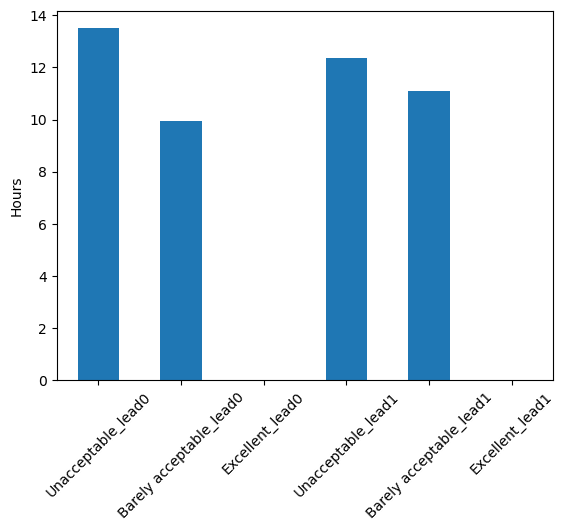

In [13]:
# plot a bar chart to show the distribution of the quality of the ECG signal
import matplotlib.pyplot as plt
def plot_quality_distribution():
    res = pd.read_csv('../data/ECG/ecg_quality_count.csv')
    res = res.drop(columns=['Patient'])
    res = res.mean()
    # convert the count to hours
    res = res * 20 / 60 / 60
    res.plot(kind='bar')
    plt.ylabel('Hours')
    # rotate the x-axis labels
    plt.xticks(rotation=45)
    plt.savefig('../figures/ecg_quality_duration.png', bbox_inches='tight')
    plt.show()
plot_quality_distribution()

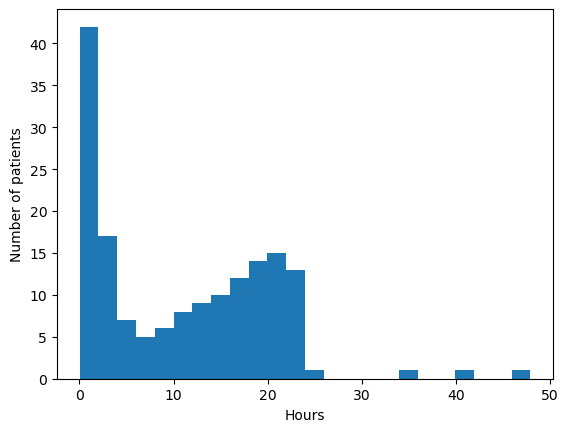

In [12]:
# plot the histogram of the ECG signal quality (barely acceptable) in lead 1 for all patients
def plot_quality_histogram():
    res = pd.read_csv('../data/ECG/ecg_quality_count.csv')
    res = res.drop(columns=['Patient'])
    res = res['Barely acceptable_lead1']
    res = res * 20 / 60 / 60
    res.plot(kind='hist', bins=24)
    plt.xlabel('Hours')
    plt.ylabel('Number of patients')
    plt.savefig('../figures/ecg_quality_histogram.png')
    plt.show()
plot_quality_histogram()

In [ ]:
# check if the dataset with ECG features is included and normalised.
import pandas as pd
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    recall_score, f1_score, confusion_matrix, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression as PlattScaling
from sklearn.decomposition import PCA
import warnings
from dataset_preprocess import DataPreprocessor
from utils import set_seed
from scipy.stats import wilcoxon
import copy
from itertools import combinations
import shap

# Ignore warnings
warnings.filterwarnings("ignore")

/home/kebl6272/anaconda3/envs/vitalsqi/lib/python3.8/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


In [2]:
# Define the label name (e.g., 'DIED', 'HFNOV', 'MEVEN')
label_name = 'DIED'
# Signal type
signal_type = 'ECG'
# Lead
lead = 1

# Set feature list to None to use all features
hrv_features = [
    'HRV_MeanNN', 'HRV_SDNN', 'HRV_RMSSD', 'HRV_SDSD', 'HRV_CVNN', 'HRV_CVSD', 'HRV_MedianNN',
    'HRV_MadNN', 'HRV_MCVNN', 'HRV_IQRNN', 'HRV_SDRMSSD', 'HRV_Prc20NN', 'HRV_Prc80NN',
    'HRV_pNN50', 'HRV_pNN20', 'HRV_MinNN', 'HRV_MaxNN', 'HRV_HTI', 'HRV_TINN', 'HRV_HF',
    'HRV_VHF', 'HRV_TP', 'HRV_HFn', 'HRV_LnHF', 'HRV_SD1', 'HRV_SD2', 'HRV_SD1SD2', 'HRV_S',
    'HRV_CSI', 'HRV_CVI', 'HRV_CSI_Modified', 'HRV_PIP', 'HRV_IALS', 'HRV_PSS', 'HRV_PAS',
    'HRV_GI', 'HRV_SI', 'HRV_AI', 'HRV_PI', 'HRV_C1d', 'HRV_C1a', 'HRV_SD1d', 'HRV_SD1a',
    'HRV_C2d', 'HRV_C2a', 'HRV_SD2d', 'HRV_SD2a', 'HRV_Cd', 'HRV_Ca', 'HRV_SDNNd',
    'HRV_SDNNa', 'HRV_DFA_alpha1', 'HRV_MFDFA_alpha1_Width', 'HRV_MFDFA_alpha1_Peak',
    'HRV_MFDFA_alpha1_Mean', 'HRV_MFDFA_alpha1_Max', 'HRV_MFDFA_alpha1_Delta',
    'HRV_MFDFA_alpha1_Asymmetry', 'HRV_MFDFA_alpha1_Fluctuation',
    'HRV_MFDFA_alpha1_Increment', 'HRV_ApEn', 'HRV_SampEn', 'HRV_ShanEn', 'HRV_FuzzyEn',
    'HRV_CD', 'HRV_HFD', 'HRV_KFD', 'HRV_LZC'
]
ecg_features = ['ECG_a_R', 'ECG_RR0', 'ECG_RR1', 'ECG_RR2', 'ECG_RRm', 'ECG_RR_0_1', 'ECG_RR_2_1', 'ECG_RR_m_1', 'ECG_t_PR', 
                'ECG_t_QR', 'ECG_t_RS',	'ECG_t_RT', 'ECG_t_PQ', 'ECG_t_PS', 'ECG_t_PT', 'ECG_t_QS', 'ECG_t_QT', 'ECG_t_ST', 
                'ECG_a_PQ', 'ECG_a_QR', 'ECG_a_RS', 'ECG_a_ST', 'ECG_a_PS', 'ECG_a_PT', 'ECG_a_QS', 'ECG_a_QT', 'ECG_a_ST_QS', 
                'ECG_a_RS_QR'] + hrv_features

# feature_type = ['mean', 'var', 'slope', 'intercept', 'rmse', 'r2']
feature_type = ['mean', 'var']
feature_list = [feature+'_'+ftype for feature in ecg_features for ftype in feature_type]

In [5]:
preprocessor = DataPreprocessor(label_name=label_name, missing_method='median', normalize=True, feature_list=feature_list, signal_type=signal_type, lead=lead)
preprocessor.split_data(method='full')
X_full, _, y_full, _ = preprocessor.get_dataset()
y_full = y_full.astype(int)

In [6]:
X_full

,ECG_a_R_mean,ECG_a_R_var,ECG_RR0_mean,ECG_RR0_var,ECG_RR1_mean,ECG_RR1_var,ECG_RR2_mean,ECG_RR2_var,ECG_RRm_mean,ECG_RRm_var,...,HRV_FuzzyEn_mean,HRV_FuzzyEn_var,HRV_CD_mean,HRV_CD_var,HRV_HFD_mean,HRV_HFD_var,HRV_KFD_mean,HRV_KFD_var,HRV_LZC_mean,HRV_LZC_var
USUBJID,,,,,,,,,,,,,,,,,,,,,
003-1001,-0.052239,-0.096322,-0.332406,-0.120338,-0.412493,-0.227134,-0.303558,-0.128202,-0.346755,-0.171209,...,0.424624,-0.015545,-1.030526,2.082563,1.310799,-1.178931,2.678249,0.388960,0.769605,-1.001679
003-1002,-0.084547,-0.094883,-0.472268,-0.118903,-0.605623,-0.222064,-0.426674,-0.126760,-0.495833,-0.167867,...,-0.000552,-0.302461,0.696372,0.737606,-1.199422,0.858896,-0.560248,-0.192372,-0.920685,0.844789
003-1003,0.016622,-0.095276,0.242932,-0.109080,0.380154,-0.180806,0.202240,-0.113357,0.265762,-0.141422,...,1.090192,-0.137951,1.530621,-0.541286,-0.349787,0.829998,-0.182435,-0.186247,0.768262,0.426715
003-1004,-0.051910,-0.096195,-0.671798,-0.124018,-0.879682,-0.242345,-0.601291,-0.132458,-0.707720,-0.180783,...,-1.344654,-1.322512,-1.044701,-0.137331,-2.145811,0.986911,-0.715868,-0.191758,-2.097545,-0.086374
003-1005,-0.024360,-0.085999,0.298031,-0.115832,0.457170,-0.207949,0.251281,-0.123234,0.324950,-0.159728,...,-0.049249,-0.208580,1.084335,0.362308,-1.394385,1.117352,-0.678434,-0.158285,-0.162517,0.751257
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
003-1255,-0.093178,-0.096402,-0.027296,-0.123462,0.007761,-0.240077,-0.035542,-0.131831,-0.022041,-0.179359,...,0.419828,2.369767,-1.095082,-1.039758,1.405245,-1.286595,0.223563,-0.165874,1.313621,-0.546413
003-1256,-0.125299,-0.096095,0.175910,-0.119628,0.288073,-0.224908,0.145379,-0.127724,0.195308,-0.169916,...,-0.067335,0.565557,0.947049,-0.074753,-0.673536,1.207565,-0.620150,-0.191739,0.018737,0.174834
003-1257,-0.180980,-0.096403,0.385099,-0.118017,0.551482,-0.221530,0.309258,-0.126348,0.403539,-0.167292,...,-1.904489,0.760768,-0.166449,0.759714,-0.914167,0.405600,-1.385052,-0.195690,-1.611143,0.521394
